In [2]:
import os
import numpy as np
import uproot
import sys

import matplotlib.pyplot as plt

## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

Welcome to JupyROOT 6.27/01


In [3]:
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
print(sys.path)

## Atown's stuff
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

# ------------- User Inputs ------------- #
NCHAN = 3
VERBOSE = False
ASK_MATPLOT = True
DO_2D = False
QVAR_USE = "qFlat"
PECUTVALUE = 0.5

defPath = str(os.environ["CF4HOME"]) + "/procData/"
rootPath = defPath + "/analysis1/"

runID_lp = [202206231023]
runID_bare = [202205201136]
physicsList = runID_bare + runID_lp
allRuns = physicsList

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp1', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/']


In [4]:
# ------------- Main Analysis ------------- #
rcList = []
fList = []

for run in allRuns:
    file_path = rootPath + f"npv1_{run}.root"
    f = ROOT.TFile(file_path, "READ")
    fList.append(f)
    tt = f.Get("tt")
    
    rcObj = RunClass(run, tt, fname = file_path)
    rcList.append(rcObj)
    
    rcObj.computeSPE(width=15, verbose=VERBOSE, varname=QVAR_USE, channels=[i for i in range(NCHAN)], nbins = 150)
    rcObj.UprootConstructor()
    # rcList.append(rcObj)

if VERBOSE:
    input("say something to move past bkg SPE plots")

for rc in rcList:
    rc.print()

rcBare = SORTING.pickSingleRC(runID_bare[0], rcList)
rcLp = SORTING.pickSingleRC(runID_lp[0], rcList)



runID: 202205201136
Nevents: 217499.00,   time: 0.65 min
average Rate: 5558.14 Hz
chID:0: spe = 146.44 +/- 0.18     maxChi2 = 145.18
chID:1: spe = 153.75 +/- 0.09     maxChi2 = 199.77
chID:2: spe = 154.97 +/- 0.09     maxChi2 = 430.11

runID: 202206231023
Nevents: 515499.00,   time: 1.19 min
average Rate: 7243.99 Hz
chID:0: spe = 149.89 +/- 0.04     maxChi2 = 962.55
chID:1: spe = 152.41 +/- 0.04     maxChi2 = 656.02
chID:2: spe = 153.36 +/- 0.04     maxChi2 = 1195.08


Warning in <TSpectrum::SearchHighRes>: Peak buffer full
2025-08-27 14:47:46.983 Python[39210:35125460] WARNING: Secure coding is not enabled for restorable state! Enable secure coding by implementing NSApplicationDelegate.applicationSupportsSecureRestorableState: and returning YES.
Info in <TCanvas::MakeDefCanvas>:  created default TCanvas with name c1
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full


In [5]:

# --------- Building Full Spectra --------- #
binHigh = 80.
Nbins = 400
binWidth = (binHigh - 0.) / Nbins
hist_bins = np.linspace(0, binHigh, Nbins + 1)
hReference = TH1F("hReference", "Reference Spectrum", int(Nbins), 0, binHigh)
hReference.Sumw2(True)

# Build all SPE spectra
for rc in rcList:
    rc.BuildSpectrum(hReference, QVAR_USE, PECUTVALUE, rate=True)

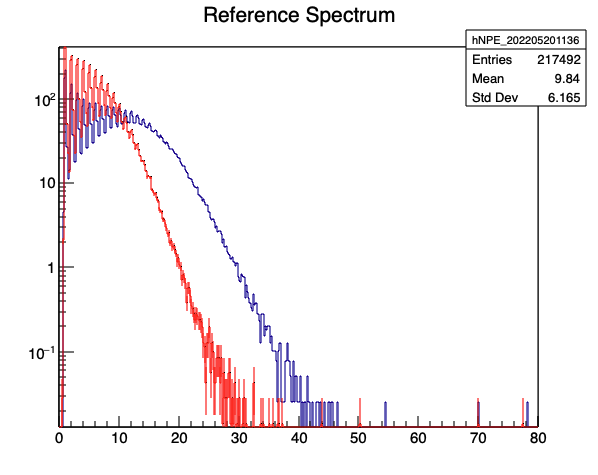

In [6]:
## plotting reference (bkg) figures 
c0 = TCanvas()
# c0.Divide(1, 2)
# c0.cd(1)
c0.SetLogy()

# hReference.GetXaxis().SetRangeUser(0, 20)
# hReference.Draw("hist")
rcList[0].GetSpectrum().Draw("hist")
# rcList[0].GetSpectrum().GetXaxis().SetRangeUser(0, 5)
for rc in rcList[1:]:
  h = rc.GetSpectrum()
  h.SetLineColor(rcList.index(rc)+1)
#   h.SetLineWidth(3)

  h.Draw("hist same E")

## set x axis
c0.cd(1)

c0.Update()
c0.Draw()

2
['chInfo', 'evTime', 'blineV', 'blineE', 'minV', 'timeMin', 'qFixed', 'qFlat', 'tFlatStart', 'tFlatEnd', 'qRCFixed', 'qRCFlat']
<TBranch 'qFixed' at 0x00030182d990>


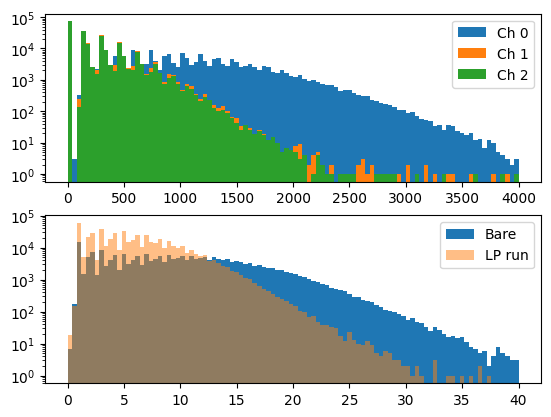

In [7]:
print(len(rcList))

## print all attributes of rcList[0] that dont include __ at start
# for attr in dir(rcList[0].mttUp):
#     if not attr.startswith("__"):
#         print(attr)

print(rcList[0].mttUp.keys())
print(rcList[0].mttUp["qFixed"])

qraw = rcBare.mttUp[QVAR_USE].array(library="np")

for rc in rcList:
    qa = rc.GetSPEValues(QVAR_USE)
qraw = rcList[0].mttUp[QVAR_USE].array(library="np")

fig, (axQ, axS) = plt.subplots(2, 1)
# plt.hist(qa, bins=50)

binEdge = np.linspace(0, 4000, 101)
axQ.hist(qraw[:, 0], bins=binEdge, label="Ch 0")
axQ.hist(qraw[:, 1], bins=binEdge, label="Ch 1")
axQ.hist(qraw[:, 2], bins=binEdge, label="Ch 2")

axQ.legend()
axQ.set_yscale("log")

bE = np.linspace(0, 40, 101)
z = axS.hist(rcBare.GetSPEArray(), bins=bE, label = "Bare")

z = axS.hist(rcLp.GetSPEArray(), bins=bE, alpha = 0.5, histtype="stepfilled", label = "LP run")

axS.set_yscale("log")
axS.legend()
plt.show()
# axS.set_yscale("log")